In [91]:
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from collections import Counter
from wordcloud import WordCloud

df = pd.read_csv("processed_products_data.csv")

In [93]:
df.shape

(3417, 11)

In [95]:
df.head()

,Название,Цена,Рассрочка,Наличие,Модель,Страна,Производитель,Описание,Изображение,Аптеки,Категории
0,Декарис 50 мг № 2 табл.,1150,288 x 4 мес.,Есть в наличии,5997001380338,Венгрия,Гедеон Рихтер,Инструкция по медицинскому применениюлекарстве...,https://st.europharma.kz/cache/product/7876/x2...,"['Аптека №57 (г.Алматы,Жетысуский район, ул. Д...","['Лекарственные средства', 'От паразитов']"
1,911 бадяга 100 мл. гель,876,219 x 4 мес.,Есть в наличии,4607010243104,Россия,Твинс-Тек,Средство создано на основе бадяги - уникальног...,https://st.europharma.kz/cache/product/4387/x2...,"['Аптека № 58, Алматы, (Акбулак) (мкр Акбулак,...","['Витамины и БАДы', 'БАДы', 'Для кожи']"
2,"Аскорбинка Витаминка ""София"" с ароматом лимона...",85,21 x 4 мес.,Есть в наличии,4870004384620,Казахстан,Ева-1 ТОО,Биологически активная добавка к пище. Не являе...,https://st.europharma.kz/cache/product/8554/40...,"['Аптека №57 (г.Алматы,Жетысуский район, ул. Д...","['Витамины и БАДы', 'Витамины и минералы', 'Дл..."
3,"La Roche Цикапласт губы барьерный бальзам 7,5 гр",5540,1 385 x 4 мес.,Есть в наличии,30106659,Россия,LA ROCHE-POSAY,Восстанавливающий бальзам-барьер La Roche-Posa...,https://st.europharma.kz/cache/product/1490/x2...,"['Аптека № 75, Алматы, Абая Жарокова) (ул.Абая...","['Красота и гигиена', 'Дермакосметика']"
4,Фрутоняня пюре морковь 4месяцев 80 г,715,179 x 4 мес.,Есть в наличии,4600338004952,Россия,АО ПРОГРЕСС (Россия),Бренд Фрутоняня Возраст 4 мес+ Вид пюре Фрукто...,https://st.europharma.kz/cache/product/26714/x...,"['Аптека №294 (Алматы ,Кульджинский тракт, 14,...","['Мать и дитя', 'Детское питание и кормление',..."


In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3417 entries, 0 to 3416
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Название       3417 non-null   object
 1   Цена           3417 non-null   int64 
 2   Рассрочка      3417 non-null   object
 3   Наличие        3417 non-null   object
 4   Модель         3417 non-null   int64 
 5   Страна         3417 non-null   object
 6   Производитель  3417 non-null   object
 7   Описание       3416 non-null   object
 8   Изображение    3417 non-null   object
 9   Аптеки         3417 non-null   object
 10  Категории      3417 non-null   object
dtypes: int64(2), object(9)
memory usage: 293.8+ KB


### Price distribution

### Goal:

How prices are distributed in general.

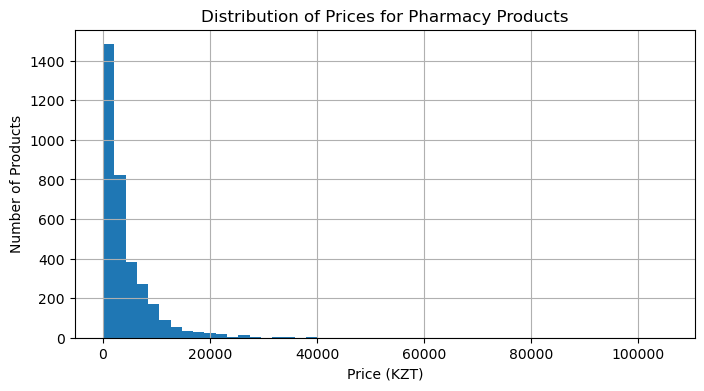

In [87]:
prices = df["Цена"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(prices, bins=50)

plt.title("Distribution of Prices for Pharmacy Products")
plt.xlabel("Price (KZT)")
plt.ylabel("Number of Products")
plt.grid(True)
plt.show()

This histogram shows how pharmacy product prices are distributed.
We can see that most products are concentrated in the lower price range.

### Price distribution without extreme outliers

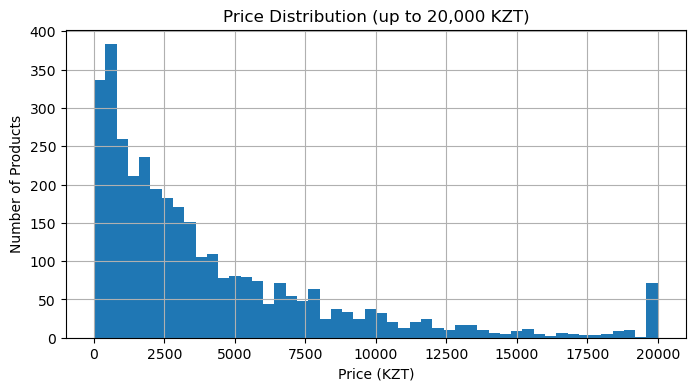

In [100]:
plt.figure(figsize=(8, 4))
plt.hist(prices.clip(upper=20000), bins=50)

plt.title("Price Distribution (up to 20,000 KZT)")
plt.xlabel("Price (KZT)")
plt.ylabel("Number of Products")
plt.grid(True)
plt.show()

Here I limited prices to 20,000 KZT to better see the mass-market segment.Most products are priced below this value.

### Top-10 product categories (bar chart)

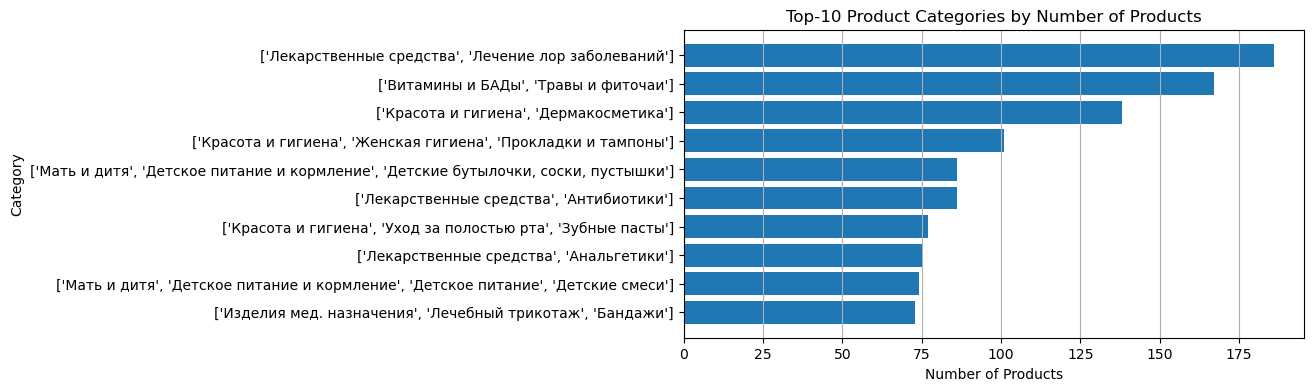

In [103]:
top_categories = df["Категории"].value_counts().head(10)

plt.figure(figsize=(8, 4))
plt.barh(top_categories.index[::-1], top_categories.values[::-1])

plt.title("Top-10 Product Categories by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.grid(axis="x")
plt.show()

This chart shows the most common product categories. A small number of categories dominate the assortment.

### Top-10 product categories (pie chart)

Only to show share, not for precise comparison.

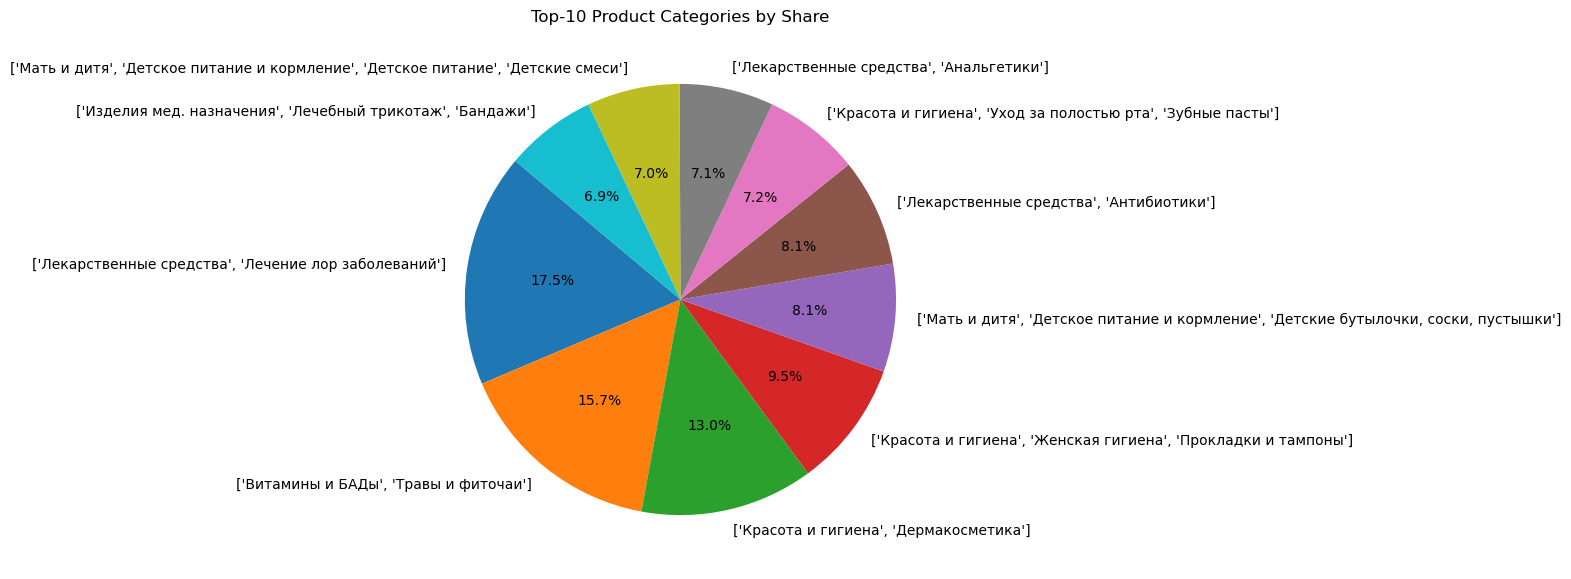

In [106]:
plt.figure(figsize=(7, 7))
plt.pie(
    top_categories.values,
    labels=top_categories.index,
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Top-10 Product Categories by Share")
plt.show()

### Top-10 pharmacies by number of products

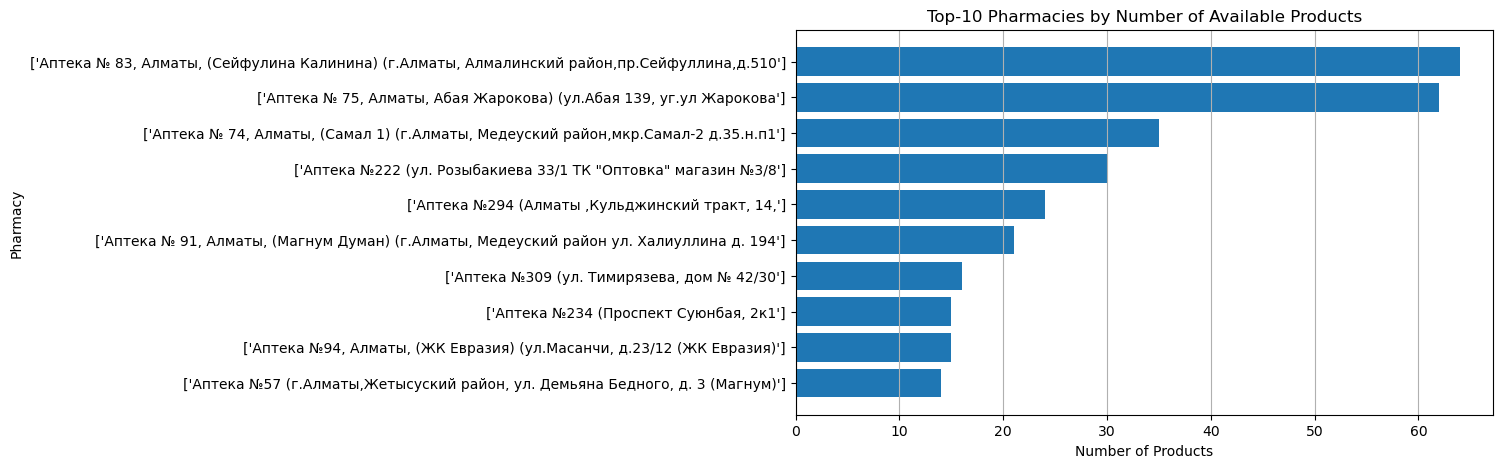

In [108]:
top_pharmacies = df["Аптеки"].value_counts().head(10)

plt.figure(figsize=(9, 5))
plt.barh(top_pharmacies.index[::-1], top_pharmacies.values[::-1])

plt.title("Top-10 Pharmacies by Number of Available Products")
plt.xlabel("Number of Products")
plt.ylabel("Pharmacy")
plt.grid(axis="x")
plt.show()

## Word cloud for manufacturer countries (visual intuition)

Not for numbers — only for visual impression

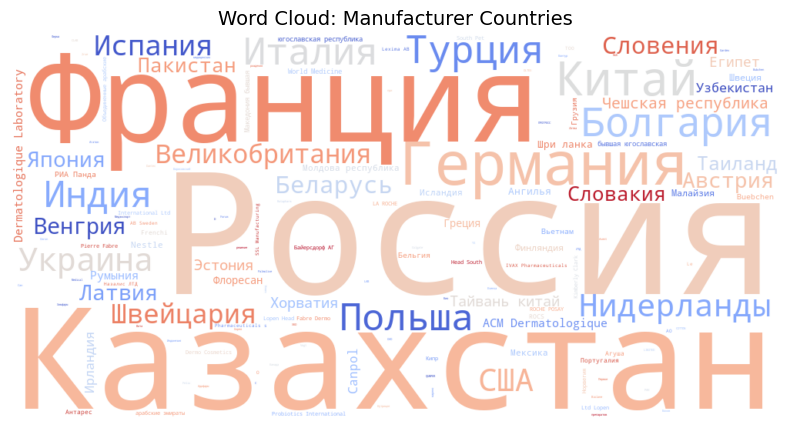

In [75]:
countries_text = " ".join(
    df["Страна"].dropna().astype(str)
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="coolwarm"
).generate(countries_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud: Manufacturer Countries", fontsize=14)
plt.show()

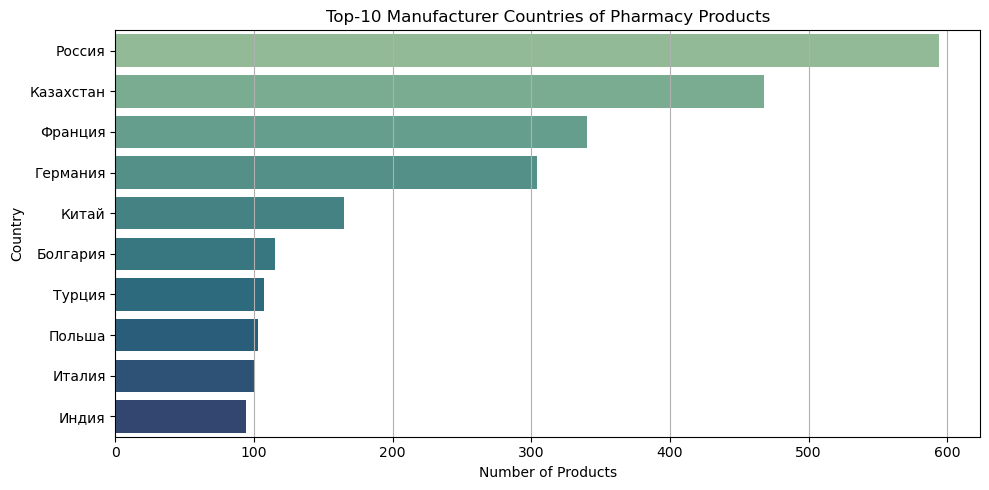

In [77]:
top_countries = df[df["Страна"] != "Нет"]["Страна"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    palette="crest"
)

plt.title("Top-10 Manufacturer Countries of Pharmacy Products")
plt.xlabel("Number of Products")
plt.ylabel("Country")
plt.grid(True, axis="x")
plt.tight_layout()
plt.show()
